# 🎓 Student Performance Prediction — Phase 4 & 5: EDA + Model Training
AIML Mini Project — comparing Logistic Regression, Decision Tree, Random Forest

## 0️⃣ Setup (self-contained: reload + preprocess)
Run this first so this notebook works even if opened fresh.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

df = pd.read_csv('../data/student_data.csv')

def score_to_grade(g):
    if g >= 16: return 'A'
    elif g >= 14: return 'B'
    elif g >= 12: return 'C'
    elif g >= 10: return 'D'
    else:         return 'F'

df['grade'] = df['G3'].apply(score_to_grade)

from sklearn.model_selection import train_test_split

# EARLY-WARNING design: predict final grade WITHOUT past grades (G1, G2)
X = df.drop(columns=['G1', 'G2', 'G3', 'grade'])
y = df['grade']
X = pd.get_dummies(X, drop_first=True, dtype=int)

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)
print("Train:", X_train.shape, "| Test:", X_test.shape)


Train: (316, 39) | Test: (79, 39)


## 1️⃣ EDA — Correlation heatmap
Which factors relate to the final score (G3)? Great figure for your report.

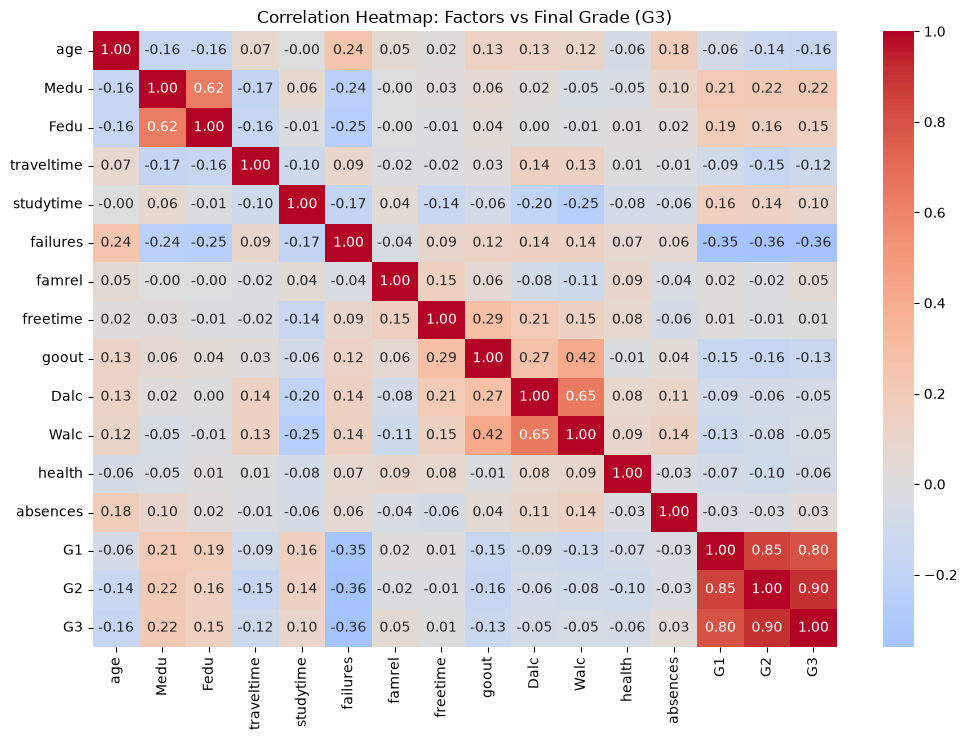

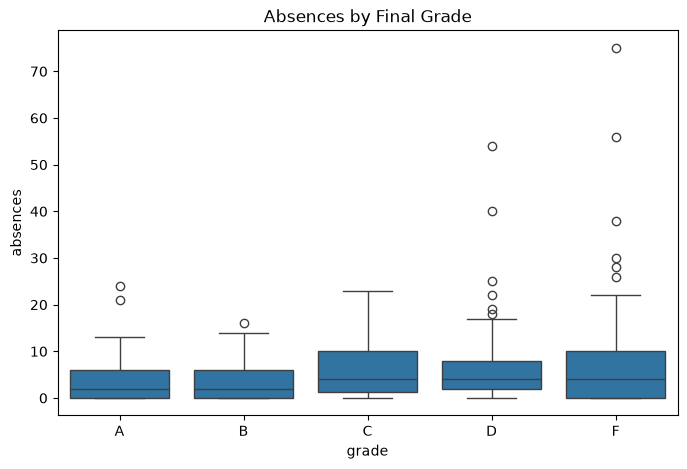

In [2]:
numeric_cols = ['age', 'Medu', 'Fedu', 'traveltime', 'studytime', 'failures',
                'famrel', 'freetime', 'goout', 'Dalc', 'Walc', 'health',
                'absences', 'G1', 'G2', 'G3']

plt.figure(figsize=(12, 8))
sns.heatmap(df[numeric_cols].corr(), annot=True, fmt='.2f', cmap='coolwarm', center=0)
plt.title('Correlation Heatmap: Factors vs Final Grade (G3)')
plt.show()

# Key insight chart: absences vs final score
plt.figure(figsize=(8, 5))
sns.boxplot(x='grade', y='absences', data=df, order=['A','B','C','D','F'])
plt.title('Absences by Final Grade')
plt.show()


## 2️⃣ Train 3 models and compare
- **Logistic Regression** — linear baseline (needs feature scaling)
- **Decision Tree** — interpretable, no scaling needed
- **Random Forest** — ensemble, usually strongest

`class_weight='balanced'` helps the model care about minority grades (like F) — remember the imbalance from Phase 3!

In [3]:
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, classification_report

models = {
    "Logistic Regression": Pipeline([
        ('scaler', StandardScaler()),
        ('clf', LogisticRegression(max_iter=2000, class_weight='balanced', random_state=42))
    ]),
    "Decision Tree": DecisionTreeClassifier(max_depth=5, class_weight='balanced', random_state=42),
    "Random Forest": RandomForestClassifier(n_estimators=200, class_weight='balanced', random_state=42)
}

results = {}
for name, model in models.items():
    model.fit(X_train, y_train)
    y_pred = model.predict(X_test)
    acc = accuracy_score(y_test, y_pred)
    results[name] = acc
    print("=" * 60)
    print(f"MODEL: {name}   |   Accuracy: {acc:.3f}")
    print("=" * 60)
    print(classification_report(y_test, y_pred))


MODEL: Logistic Regression   |   Accuracy: 0.253
              precision    recall  f1-score   support

           A       0.14      0.25      0.18         8
           B       0.08      0.08      0.08        12
           C       0.06      0.08      0.07        12
           D       0.31      0.24      0.27        21
           F       0.55      0.42      0.48        26

    accuracy                           0.25        79
   macro avg       0.23      0.22      0.22        79
weighted avg       0.30      0.25      0.27        79

MODEL: Decision Tree   |   Accuracy: 0.241
              precision    recall  f1-score   support

           A       0.13      0.25      0.17         8
           B       0.16      0.42      0.23        12
           C       0.11      0.08      0.10        12
           D       0.33      0.10      0.15        21
           F       0.50      0.35      0.41        26

    accuracy                           0.24        79
   macro avg       0.25      0.24      

## 3️⃣ Results comparison table

              Model  Accuracy
      Random Forest  0.341772
Logistic Regression  0.253165
      Decision Tree  0.240506


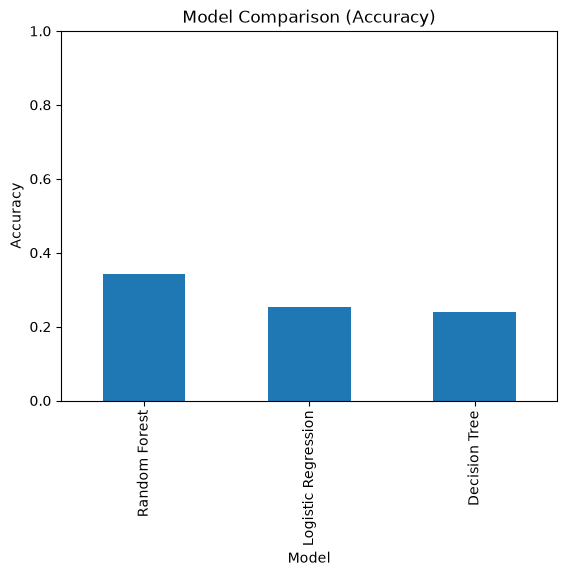

In [6]:
results_df = pd.DataFrame(list(results.items()), columns=['Model', 'Accuracy'])
results_df = results_df.sort_values('Accuracy', ascending=False).reset_index(drop=True)
print(results_df.to_string(index=False))

results_df.plot(x='Model', y='Accuracy', kind='bar', legend=False,
                title='Model Comparison (Accuracy)')
plt.ylabel('Accuracy')
plt.ylim(0, 1)
plt.show()


## 4️⃣ Deep-dive: Confusion matrix of the best model
Shows WHERE the model confuses grades (e.g., predicting C when truth is D).

Best model: Random Forest (0.342)


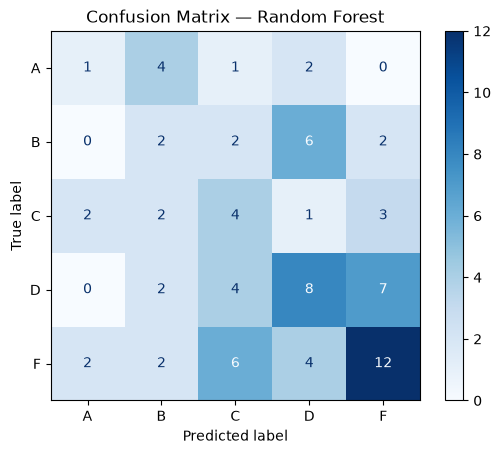

In [4]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

best_name = max(results, key=results.get)
print(f"Best model: {best_name} ({results[best_name]:.3f})")

best_model = models[best_name]
y_pred = best_model.predict(X_test)

cm = confusion_matrix(y_test, y_pred, labels=['A','B','C','D','F'])
disp = ConfusionMatrixDisplay(cm, display_labels=['A','B','C','D','F'])
disp.plot(cmap='Blues')
plt.title(f'Confusion Matrix — {best_name}')
plt.show()


## 5️⃣ ⭐ BONUS EXPERIMENT: What if we knew past grades?
Add G1 + G2 back and watch accuracy jump. This is a fantastic viva/report section:
*"Past performance is the strongest predictor — but an early-warning system must work without it."* 

In [5]:
X2 = df.drop(columns=['G3', 'grade'])   # keep G1, G2 this time
X2 = pd.get_dummies(X2, drop_first=True, dtype=int)

X2_train, X2_test, y2_train, y2_test = train_test_split(
    X2, y, test_size=0.2, random_state=42, stratify=y
)

rf_past = RandomForestClassifier(n_estimators=200, class_weight='balanced', random_state=42)
rf_past.fit(X2_train, y2_train)
past_acc = accuracy_score(y2_test, rf_past.predict(X2_test))

print(f"Random Forest WITHOUT past grades (early warning): {results['Random Forest']:.3f}")
print(f"Random Forest WITH G1+G2:                          {past_acc:.3f}")


Random Forest WITHOUT past grades (early warning): 0.342
Random Forest WITH G1+G2:                          0.696
